In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from pymoo.core.problem import Problem
from pymoo.core.repair import Repair
from pymoo.algorithms.soo.nonconvex.ga import GA
from pymoo.optimize import minimize
from pymoo.termination import get_termination
import matplotlib.pyplot as plt

class RegressionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(7, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.net(x)

model = RegressionMLP()
model.load_state_dict(torch.load('BPNN_TPU90A.pth', weights_only=True))
model.eval()
print('BPNN (TPU90A) loaded.')

# shape (7,) → [L, H, t, b/a, L/H, t/L, t/H]
x_min_data = np.load('x_min_data_TPU90A.npy')
x_max_data = np.load('x_max_data_TPU90A.npy')
y_min_data = np.load('y_min_data_TPU90A.npy')
y_max_data = np.load('y_max_data_TPU90A.npy')
print(f'Normalization parameters loaded.  x shape: {x_min_data.shape}')

# ── 형상 제약 상수 ──
A_PLUS_B = 12.0    # a + b (타원 두 반경의 합).
MIN_GAP  = 2.0     # gap_y 하한 (mm)
L_MARGIN = 1.2     # L >= 2*(a + L_MARGIN)

ROUND_EPS = 0.01

def ab_from_e(e):
    """b/a = e 에서 타원 반경 a, b를 복원한다 (a + b = 12 구속)."""
    a = A_PLUS_B / (1.0 + e)
    return a, A_PLUS_B - a

def gap_y_of(H, t, e):
    _, b = ab_from_e(e)
    return H / 2.0 - t - b

_df = pd.read_csv('results.csv')
_d  = _df[(_df['Status'] == 'SUCCESS') & (_df['PBC_Pair_Fail'] == 0) & (_df['eps_y'] != 0)]
_gap    = _d['H'] / 2 - _d['t'] - _d['b']
_bad_g1 = int((_gap < MIN_GAP - 1e-6).sum())
_bad_g2 = int((_d['L'] < 2 * (_d['a'] + L_MARGIN) - 1e-6).sum())
print(f'학습셋 {len(_d)}개 검사 | g1 위반 {_bad_g1}개 | g2 위반 {_bad_g2}개 | '
      f'gap_y {_gap.min():.3f} ~ {_gap.max():.3f} '
      f'(하한 접촉 {int((abs(_gap - MIN_GAP) <= 1e-3).sum())}개)')
assert _bad_g1 == 0 and _bad_g2 == 0, '제약식이 샘플링 코드와 어긋난다 → 상수를 확인할 것'

TARGETS = {
    # key       label      nu*   sigma*
    'target': ('기준 목표', -0.40, 1.90)
}

DIFFICULTY = 'target'

difficulty_label, y1_target, y2_target = TARGETS[DIFFICULTY]

y1_target_norm = (y1_target - y_min_data[0]) / (y_max_data[0] - y_min_data[0])
y2_target_norm = (y2_target - y_min_data[1]) / (y_max_data[1] - y_min_data[1])

print(f"난이도: {difficulty_label} ({DIFFICULTY})")
print(f"Target | Poisson's ratio: {y1_target}  |  Max Eqv Stress: {y2_target} MPa")
print(f'Normalized target | y1: {y1_target_norm:.4f}  |  y2: {y2_target_norm:.4f}')

_near = _d[(_d['Poisson_Ratio'] - y1_target).abs() <= 0.03]
if len(_near) < 5:
    print(f'  [경고] 목표 ν 근방(±0.03)의 실측 표본이 {len(_near)}개뿐이다. 외삽 위험이 크다.')
else:
    _lo, _hi = _near['Max_Eqv_Stress_MPa'].min(), _near['Max_Eqv_Stress_MPa'].max()
    if _lo <= y2_target <= _hi:
        print(f'  [OK] ν 근방 실측 {len(_near)}개의 응력 범위 {_lo:.3f} ~ {_hi:.3f} MPa 안에 '
              f'목표 {y2_target} MPa가 있다.')
    else:
        print(f'  [경고] ν 근방 실측 {len(_near)}개의 응력 범위는 {_lo:.3f} ~ {_hi:.3f} MPa인데 '
              f'목표가 {y2_target} MPa다. 물리적으로 도달 불가일 수 있다.')

BPNN (TPU90A) loaded.
Normalization parameters loaded.  x shape: (7,)
학습셋 989개 검사 | g1 위반 0개 | g2 위반 0개 | gap_y 2.000 ~ 12.265 (하한 접촉 154개)
난이도: 기준 목표 (target)
Target | Poisson's ratio: -0.4  |  Max Eqv Stress: 1.9 MPa
Normalized target | y1: 0.2119  |  y2: 0.4648
  [OK] ν 근방 실측 12개의 응력 범위 1.721 ~ 2.344 MPa 안에 목표 1.9 MPa가 있다.


In [2]:
w1 = 1.0   # 포아송비 오차 가중치
w2 = 1.0   # 최대 등가 응력 오차 가중치

xl = x_min_data[:4]   # GA 탐색 범위 하한: [L, H, t, b/a] 최솟값
xu = x_max_data[:4]   # GA 탐색 범위 상한: [L, H, t, b/a] 최댓값

class GeometryRepair(Repair):
    def _do(self, problem, X, **kwargs):
        X = X.copy()
        a, b = ab_from_e(X[:, 3])

        H_min = 2.0 * b + 2.0 * X[:, 2] + 2.0 * MIN_GAP + ROUND_EPS
        X[:, 1] = np.minimum(np.maximum(X[:, 1], H_min), problem.xu[1])

        L_min = 2.0 * (a + L_MARGIN)
        X[:, 0] = np.minimum(np.maximum(X[:, 0], L_min), problem.xu[0])
        return X

class EAREInverseProblem(Problem):
    def __init__(self):
        super().__init__(
            n_var        = 4,          # 설계변수: L, H, t, b/a
            n_obj        = 1,
            n_ieq_constr = 0,
            xl           = xl,
            xu           = xu
        )

    def _evaluate(self, X, out, *args, **kwargs):
        L   = X[:, 0]
        H   = X[:, 1]
        t   = X[:, 2]
        # 파생 피처 계산 (BPNN 학습 시와 동일한 방식)
        X7 = np.column_stack([L, H, t, X[:, 3],
                              L / H,    # x5: L/H
                              t / L,    # x6: t/L
                              t / H])   # x7: t/H

        X_norm   = (X7 - x_min_data) / (x_max_data - x_min_data)
        x_tensor = torch.FloatTensor(X_norm)

        with torch.no_grad():
            y_pred_norm = model(x_tensor).numpy()

        err = w1 * (y_pred_norm[:, 0] - y1_target_norm)**2 \
            + w2 * (y_pred_norm[:, 1] - y2_target_norm)**2

        out['F'] = err.reshape(-1, 1)

In [3]:
# ── Multi-start GA ──
from time import perf_counter
import platform

np.random.seed(0)
seeds     = np.random.randint(0, 100000, size=20).tolist()
poisson_tol    = 0.01
stress_tol_mpa = 0.05
 
threshold = w1 * (poisson_tol / (y_max_data[0] - y_min_data[0]))**2 \
          + w2 * (stress_tol_mpa / (y_max_data[1] - y_min_data[1]))**2
print(f"threshold (normalized) = {threshold:.6f}  "
      f"← 포아송비 ±{poisson_tol}, 응력 ±{stress_tol_mpa} MPa 기준")

# ── 역설계 인퍼런스 시간 측정 설정 ──
POP_SIZE     = 100
N_GEN        = 300
SAVE_HISTORY = True

problem     = EAREInverseProblem()
termination = get_termination('n_gen', N_GEN)

all_x       = []
all_f       = []
all_y       = []
all_x_rej   = []
all_f_rej   = []
all_y_rej   = []
conv_curves = []
run_times   = []   # 시드 1개당 GA 1회의 벽시계 시간 (초)
n_evals     = []   # 시드 1개당 대체모델 평가 횟수 (중복 제거로 pop*gen보다 작을 수 있다)

print(f'Running Multi-start GA ({len(seeds)} runs)...')
print('=' * 60)

for seed in seeds:
    t_start = perf_counter()
    result = minimize(
        problem,
        GA(pop_size=POP_SIZE, eliminate_duplicates=True, repair=GeometryRepair()),
        termination,
        seed         = seed,
        verbose      = False,
        save_history = SAVE_HISTORY
    )
    run_times.append(perf_counter() - t_start)
    n_evals.append(getattr(result.algorithm.evaluator, 'n_eval', POP_SIZE * N_GEN))

    if SAVE_HISTORY:
        history_f = [algo.pop.get('F').min() for algo in result.history]
        conv_curves.append(history_f)

    x_best = np.round(result.X, 3)
    f_best = float(result.F.flatten()[0])

    if f_best < threshold:

        L_b, H_b, t_b = x_best[0], x_best[1], x_best[2]
        x7_best  = np.array([L_b, H_b, t_b, x_best[3],
                              L_b/H_b, t_b/L_b, t_b/H_b]).reshape(1, -1)
        X_norm   = (x7_best - x_min_data) / (x_max_data - x_min_data)
        x_tensor = torch.FloatTensor(X_norm)
        with torch.no_grad():
            y_pred_norm = model(x_tensor).numpy().flatten()
        y_best = y_pred_norm * (y_max_data - y_min_data) + y_min_data

        all_x.append(x_best)
        all_f.append(f_best)
        all_y.append(y_best)
        status = 'accepted'
    else:
        L_b, H_b, t_b = x_best[0], x_best[1], x_best[2]
        x7_best  = np.array([L_b, H_b, t_b, x_best[3],
                              L_b/H_b, t_b/L_b, t_b/H_b]).reshape(1, -1)
        X_norm   = (x7_best - x_min_data) / (x_max_data - x_min_data)
        x_tensor = torch.FloatTensor(X_norm)
        with torch.no_grad():
            y_pred_norm = model(x_tensor).numpy().flatten()
        y_best = y_pred_norm * (y_max_data - y_min_data) + y_min_data
        all_x_rej.append(x_best)
        all_f_rej.append(f_best)
        all_y_rej.append(y_best)
        status = 'rejected'

    print(f'  seed {seed:>6} | error = {f_best:.6f} | {status}')

print('=' * 60)
print(f'\nAccepted solutions: {len(all_x)} / {len(seeds)}')

run_times = np.array(run_times)
n_evals   = np.array(n_evals)

print('\n' + '=' * 72)
print('  역설계 인퍼런스 시간 (대체모델 학습 제외, GA 탐색만)')
print('=' * 72)
print(f"  환경          : {platform.machine()} | torch {torch.__version__} | "
      f"threads {torch.get_num_threads()} | save_history={SAVE_HISTORY}")
print(f"  GA 설정       : pop {POP_SIZE} x {N_GEN}세대 x 시드 {len(seeds)}개")
print(f"  GA 1회        : {run_times.mean():.3f} +- {run_times.std():.3f} s  "
      f"(최소 {run_times.min():.3f} / 최대 {run_times.max():.3f})")
print(f"  목표 1개 전체 : {run_times.sum():.2f} s   <- multi-start {len(seeds)}회 합계")
print(f"  대체모델 평가 : {n_evals.sum():,}개 설계  ->  "
      f"{run_times.sum() / n_evals.sum() * 1e6:.1f} us/설계")
print('=' * 72)

threshold (normalized) = 0.001005  ← 포아송비 ±0.01, 응력 ±0.05 MPa 기준
Running Multi-start GA (20 runs)...
  seed  68268 | error = 0.000000 | accepted
  seed  43567 | error = 0.000000 | accepted
  seed  42613 | error = 0.000000 | accepted
  seed  45891 | error = 0.000000 | accepted
  seed  21243 | error = 0.000000 | accepted
  seed  95939 | error = 0.000000 | accepted
  seed  97639 | error = 0.000000 | accepted
  seed  41993 | error = 0.000000 | accepted
  seed  86293 | error = 0.000000 | accepted
  seed  55026 | error = 0.000000 | accepted
  seed  80471 | error = 0.000000 | accepted
  seed  80966 | error = 0.000000 | accepted
  seed  48600 | error = 0.000000 | accepted
  seed  39512 | error = 0.000000 | accepted
  seed  52620 | error = 0.000000 | accepted
  seed  80186 | error = 0.000000 | accepted
  seed  17089 | error = 0.000000 | accepted
  seed  32230 | error = 0.000000 | accepted
  seed  18983 | error = 0.000000 | accepted
  seed  89688 | error = 0.000000 | accepted

Accepted solutions

In [4]:
DOM_TOL = 1e-3

if len(all_x) > 0:
    all_x = np.array(all_x)
    all_y = np.array(all_y)
    all_f = np.array(all_f)
    all_a, all_b = ab_from_e(all_x[:, 3])
    all_gap = gap_y_of(all_x[:, 1], all_x[:, 2], all_x[:, 3])

    in_box  = np.all((all_x >= xl - DOM_TOL) & (all_x <= xu + DOM_TOL), axis=1)
    all_dom = np.where((all_gap >= MIN_GAP - DOM_TOL) & in_box, 'YES', 'NO')

    print('\n' + '=' * 128)
    print(f"  난이도: {difficulty_label} ({DIFFICULTY})")
    print(f"  Target | Poisson's ratio: {y1_target:.4f}  |  Max Eqv Stress: {y2_target:.2f} MPa")
    print('-' * 128)
    print(f"  {'#':>3}  {'x1(l)':>9}  {'x2(h)':>9}  {'x3(t)':>9}  {'x4(e)':>9}  "
          f"{'a':>7}  {'b':>7}  {'gap_y':>7}  {'dom':>4}  "
          f"{'Poisson':>10}  {'Stress(MPa)':>11}  {'error':>10}")
    print('-' * 128)
    for i, (xi, ai, bi, gi, di, yi, fi) in enumerate(
            zip(all_x, all_a, all_b, all_gap, all_dom, all_y, all_f)):
        print(f"  {i+1:>3}  {xi[0]:>9.3f}  {xi[1]:>9.3f}  {xi[2]:>9.4f}  {xi[3]:>9.4f}  "
              f"{ai:>7.3f}  {bi:>7.3f}  {gi:>7.3f}  {di:>4}  "
              f"{yi[0]:>10.4f}  {yi[1]:>11.3f}  {fi:>10.6f}")
    print('=' * 128)
    _n_out = int((all_dom == 'NO').sum())
    print(f"  gap_y {all_gap.min():.3f} ~ {all_gap.max():.3f}  (하한 {MIN_GAP})  |  "
          f"도메인 밖 해 {_n_out}개")
    if _n_out:
        print('  [경고] 도메인 밖 해가 있다. repair가 걸렸는지 확인할 것.')
else:
    print(f'No solutions found. (난이도 {difficulty_label}, 목표 ν={y1_target}, σ={y2_target} MPa)')
    if len(all_f_rej) > 0:
        print(f'  최적해의 정규화 오차 최솟값: {min(all_f_rej):.6f}  (threshold {threshold:.6f})')
    all_x = np.array([]).reshape(0, 4)
    all_y = np.array([]).reshape(0, 2)
    all_f = np.array([])
    all_a   = np.array([])
    all_b   = np.array([])
    all_gap = np.array([])
    all_dom = np.array([])


  난이도: 기준 목표 (target)
  Target | Poisson's ratio: -0.4000  |  Max Eqv Stress: 1.90 MPa
--------------------------------------------------------------------------------------------------------------------------------
    #      x1(l)      x2(h)      x3(t)      x4(e)        a        b    gap_y   dom     Poisson  Stress(MPa)       error
--------------------------------------------------------------------------------------------------------------------------------
    1     26.024     26.252     2.3390     2.6610    3.278    8.722    2.065   YES     -0.4000        1.900    0.000000
    2     26.060     26.422     2.3830     2.7680    3.185    8.815    2.013   YES     -0.3999        1.900    0.000000
    3     26.478     27.056     2.3720     2.7810    3.174    8.826    2.330   YES     -0.4001        1.900    0.000000
    4     25.899     26.021     2.3250     2.6150    3.320    8.680    2.005   YES     -0.3998        1.900    0.000000
    5     28.324     29.546     2.3080     2.7290    3

그림 저장 완료: GA_TPU90A_target_result.png


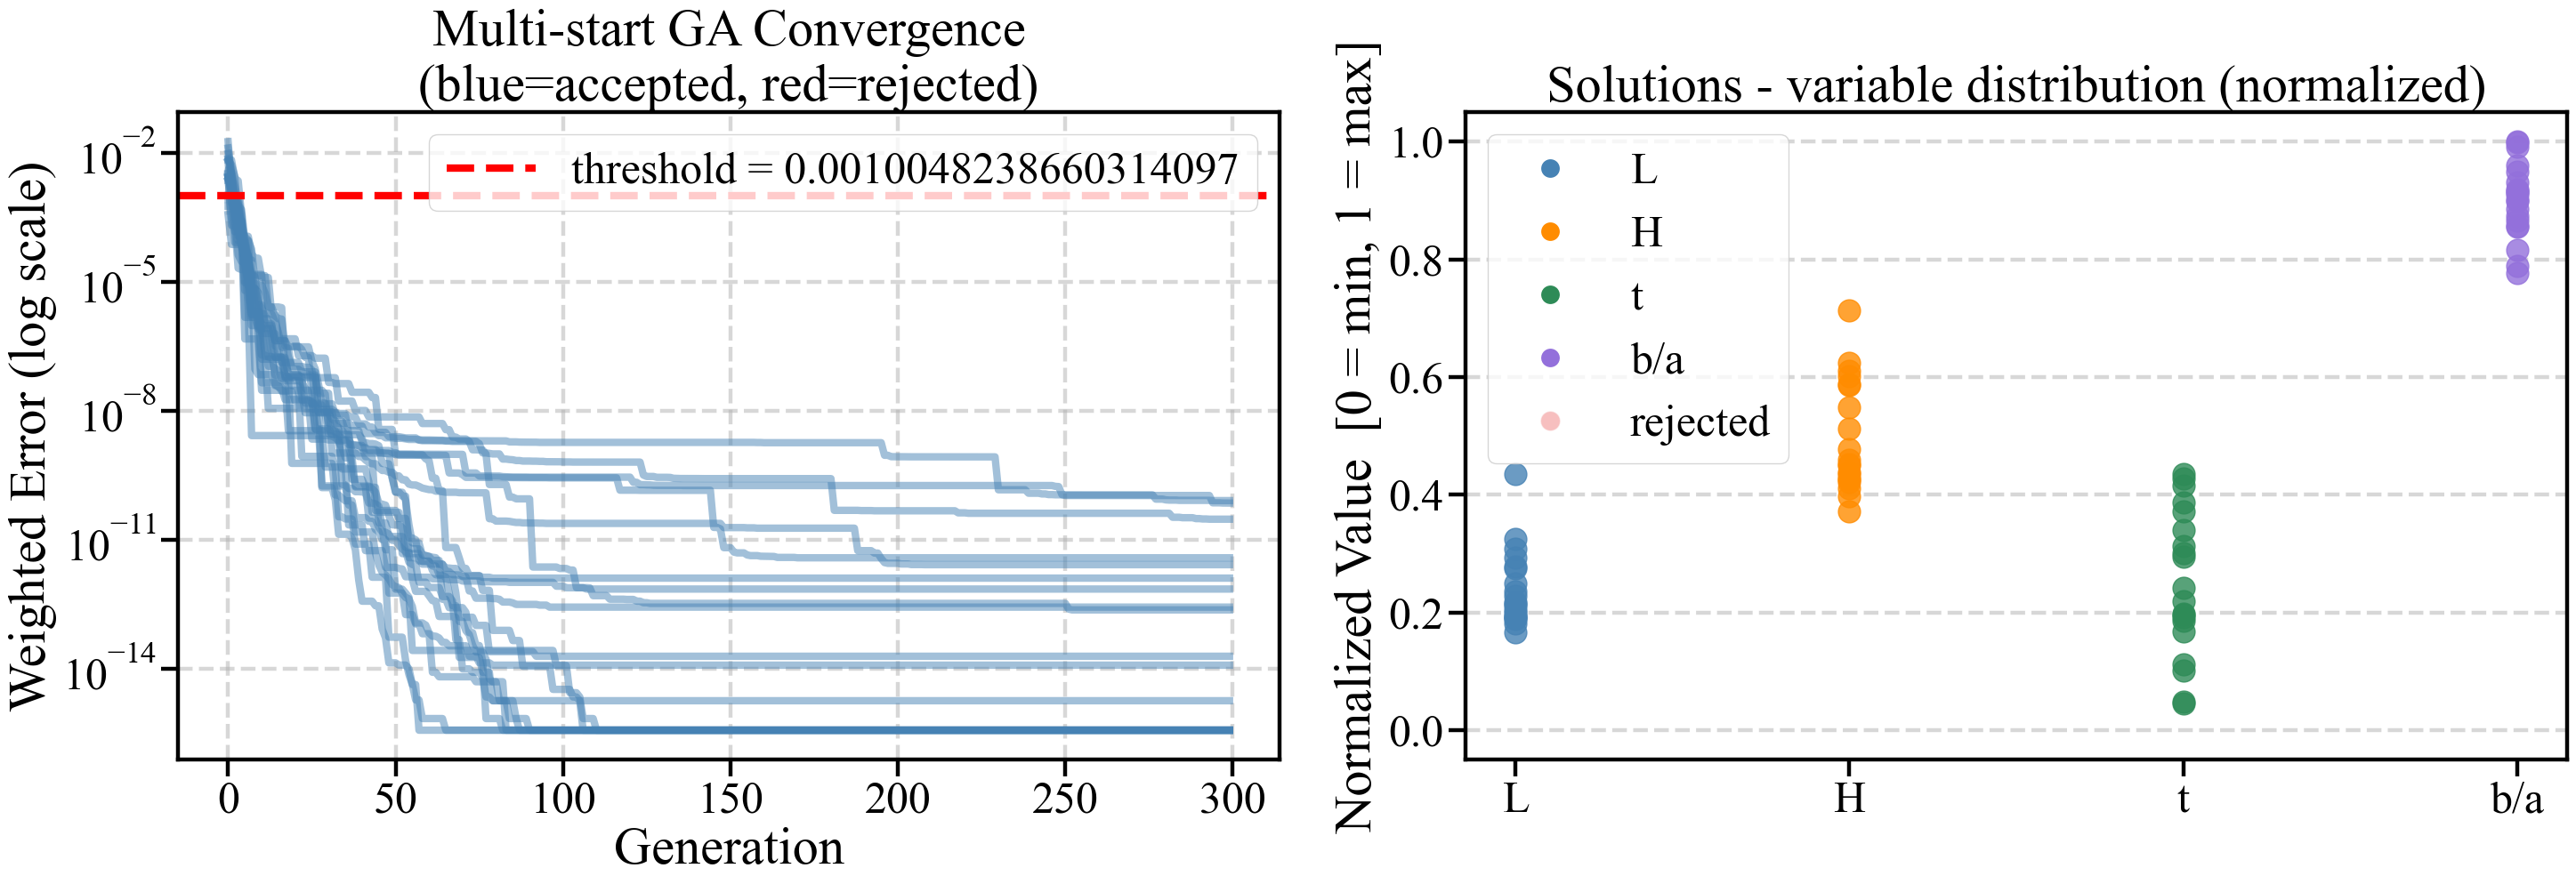

In [5]:
FONT_SCALE = 3.0   # 글자 배율 (matplotlib 기본: 제목 12 / 축이름·눈금·범례 10)
LINE_SCALE = 4.0   # 선 굵기 배율 (기본 1.5)
MARKER_SCALE = 2.0 # 마커 크기 배율 (기본 6). 점이 겹쳐 뭉개지지 않도록 선과 따로 둔다.
plt.rcParams.update({
    'font.family':       'serif',
    'font.serif':        ['Times New Roman', 'Times', 'STIXGeneral', 'DejaVu Serif'],
    'font.size':         14 * FONT_SCALE,
    'axes.titlesize':    14 * FONT_SCALE,
    'axes.labelsize':    14 * FONT_SCALE,
    'xtick.labelsize':   12 * FONT_SCALE,
    'ytick.labelsize':   12 * FONT_SCALE,
    'legend.fontsize':   12 * FONT_SCALE,
    'lines.linewidth':   1.5 * LINE_SCALE,
    'lines.markersize':  6.0 * MARKER_SCALE,
    'axes.linewidth':    0.8 * LINE_SCALE,
    'grid.linewidth':    0.8 * LINE_SCALE,
    'xtick.major.width': 0.8 * LINE_SCALE,
    'ytick.major.width': 0.8 * LINE_SCALE,
    'xtick.major.size':  3.5 * LINE_SCALE,
    'ytick.major.size':  3.5 * LINE_SCALE,
})

fig, axes = plt.subplots(1, 2, figsize=(30, 11))

for curve in conv_curves:
    color = 'steelblue' if curve[-1] < threshold else 'lightcoral'
    axes[0].plot(curve, alpha=0.5, linewidth=1.5 * LINE_SCALE, color=color)

axes[0].axhline(threshold, color='red', linestyle='--', linewidth=1.5 * LINE_SCALE,
                label=f'threshold = {threshold}')
axes[0].set_yscale('log')
axes[0].set_title('Multi-start GA Convergence\n(blue=accepted, red=rejected)')
axes[0].set_xlabel('Generation')
axes[0].set_ylabel('Weighted Error (log scale)')
axes[0].grid(True, which='both', linestyle='--', alpha=0.5)
axes[0].legend()

labels = ['L', 'H', 't', 'b/a']
colors = ['steelblue', 'darkorange', 'seagreen', 'mediumpurple']

if len(all_x_rej) > 0:
    all_x_rej_arr = np.array(all_x_rej)
    all_x_rej_norm = (all_x_rej_arr - xl) / (xu - xl)
    for j, (label, color) in enumerate(zip(labels, colors)):
        axes[1].scatter([label] * len(all_x_rej), all_x_rej_norm[:, j],
                        s=60 * MARKER_SCALE**2, alpha=0.3, color='lightcoral', zorder=2)

if len(all_x) > 0:
    all_x_norm = (all_x - xl) / (xu - xl)
    for j, (label, color) in enumerate(zip(labels, colors)):
        axes[1].scatter([label] * len(all_x), all_x_norm[:, j],
                        s=80 * MARKER_SCALE**2, alpha=0.8, color=color, label=label, zorder=3)

from matplotlib.lines import Line2D
legend_elements = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c,
                           markersize=8 * MARKER_SCALE, label=l) for l, c in zip(labels, colors)]
legend_elements += [Line2D([0],[0], marker='o', color='w', markerfacecolor='lightcoral',
                            markersize=8 * MARKER_SCALE, alpha=0.5, label='rejected')]
axes[1].legend(handles=legend_elements)

title = 'Solutions - variable distribution (normalized)'
if len(all_x) == 0:
    title += '\n(no accepted solutions)'
axes[1].set_title(title)
axes[1].set_ylabel('Normalized Value  [0 = min, 1 = max]')
axes[1].set_ylim(-0.05, 1.05)
axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = f'GA_TPU90A_{DIFFICULTY}_result.png'
plt.savefig(fig_path, dpi=300)
print(f'그림 저장 완료: {fig_path}')
plt.show()

In [6]:
import pandas as pd

if len(all_x) > 0:
    df = pd.DataFrame({
        'x1(l)':       all_x[:, 0],
        'x2(h)':       all_x[:, 1],
        'x3(t)':       all_x[:, 2],
        'x4(e)':       all_x[:, 3],
        'a':           all_a,
        'b':           all_b,
        'gap_y':       all_gap,
        'in_domain':   all_dom,
        'Poisson':     all_y[:, 0],
        'Stress(MPa)': all_y[:, 1],
        'error':       all_f,
    })

    csv_path = f'GA_results_TPU90A_{DIFFICULTY}.csv'
    df.index = df.index + 1
    df.to_csv(csv_path, index_label='#', float_format='%.4f')
    print(f'CSV 저장 완료: {csv_path}  ({len(df)}개 솔루션)')
else:
    print(f'해 없음. 저장하지 않는다 (난이도 {difficulty_label}).')

CSV 저장 완료: GA_results_TPU90A_target.csv  (20개 솔루션)
